# Investigate interpreting decoder in MEDAL

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import medal 
import torch
from captum.attr import FeatureAblation
from captum.attr import IntegratedGradients

/Users/clairehe/anaconda3/envs/medal_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-07 15:47:24,752	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-07 15:47:26,244	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [14]:
# Construct counter example for reconstruction error -based FI
eps = 0.1 # nuisance intensity
Z = np.array([[1, 0, 0, 0],[0, 0, 1, 0]])
D = np.array([0, eps, 0, 0])
N = 200
X = np.zeros((4*N, 4))
X[:N, :] = np.random.multivariate_normal(mean=Z[0,:]+D, cov=np.eye(4), size=(N, ))
X[N:2*N, :] = np.random.multivariate_normal(mean=Z[0,:]-D, cov=np.eye(4), size=(N, ))
X[2*N:3*N, :] = np.random.multivariate_normal(mean=Z[1, :], cov=np.eye(4), size=(N, ))
X[3*N:, :] = np.random.multivariate_normal(mean=np.zeros(4,), cov=np.eye(4), size=(N, ))

TypeError: only integer scalar arrays can be converted to a scalar index

In [7]:
df_fi = pd.DataFrame({"encoder_ig":data['encoder_ig'], "ae_ig":data['autoencoder_ig'], 
             "recon_ig_abs":data['recon_loss_ig_abs'], "recon_ig_signed":data['recon_loss_ig_signed']})

In [9]:
df_fi['col'] = [f'pc_{i}' for i in range(100)]

In [13]:
model = medal.load_model(
    ckpt_path = path+'medal_umap2_6_seed0_ckpts/final.pt',
    input_dim = 100,
    hidden_dims = (512, 512, 512, 512),
    latent_dim = 2,
    activation = "SELU",
    use_batchnorm = True,
    dropout_rate = 0.1)

Z = medal.get_teacher_embeddings(method='umap', X=X_test, n_components=2, random_state=0, save_path=path+'embeddings/umap2_6_seed0.npy')

/Users/clairehe/anaconda3/envs/medal_env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [20]:
Z.shape, df_fi.shape

((7680, 2), (100, 5))

ValueError: 'c' argument has 100 elements, which is inconsistent with 'x' and 'y' with size 7680.

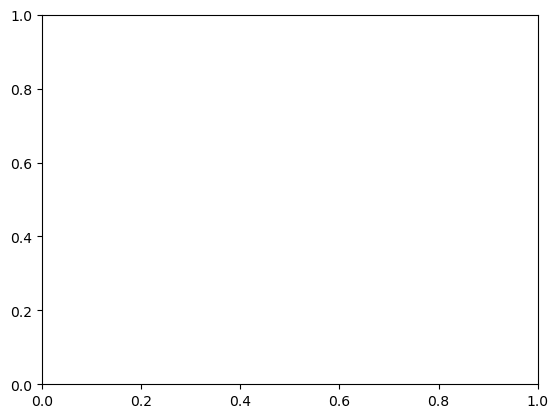

In [ ]:
plt.scatter(Z[:, 0], Z[:, 1], c=df_fi['encoder_ig'])

In [31]:
mc1_pc

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
labels,,,,,,,,,,,,,,,,,,,,,
Cones,-11.776946,-8.815241,-0.330700,3.774181,-8.587637,-0.261441,-0.872255,-0.104752,3.892506,-0.392979,...,0.258567,-0.168343,1.477878,0.148205,-0.697808,-0.154616,1.772613,1.160493,0.142944,-0.219951
RGC,-0.746612,6.160279,-0.443658,-0.108751,-0.432100,-0.351511,-1.293867,-0.005257,-0.575572,1.219481,...,0.485462,0.681347,1.330112,0.309080,-0.230080,0.515897,-0.339918,0.158077,-0.582221,-1.048702
RGC,0.739780,7.126234,-0.379869,-2.646546,-1.409249,-0.051319,-0.681447,0.078970,2.311743,-0.839656,...,-2.970773,2.285213,-1.990134,-0.403549,0.065886,-0.874032,-1.201728,-0.668084,1.838258,-0.339336
RGC,0.457695,6.886260,-0.691774,-2.247690,-1.296913,-0.870004,-1.266475,-0.064396,0.394891,0.186045,...,0.360098,-0.150446,-0.449614,-0.595476,-0.635094,-0.499496,-0.271092,-0.271175,-0.262991,-0.648135
RGC,0.405411,6.509744,-0.626103,-1.287266,-0.940090,-0.507148,1.777808,-0.075937,-1.574124,1.103085,...,-0.879254,-0.752067,-0.083475,0.316787,-0.510215,-0.375126,0.124038,-0.022257,-0.078283,0.757711
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RGC,-1.019706,5.746196,-0.557428,0.506017,-0.588375,-0.448996,0.097814,-0.005726,-2.441503,1.754690,...,-0.998610,1.163877,-0.376231,-0.272866,-0.374963,0.480748,0.697792,0.235100,-0.400267,0.046880
Cones,-2.494657,1.683162,-0.165139,5.883405,5.263242,1.756660,-2.302289,-0.170081,1.580658,3.770360,...,0.961532,0.593997,0.574611,0.192471,-0.121689,0.119855,-0.474035,-0.167624,-0.302775,-0.480841
Rods,-9.462354,-8.592255,-0.146397,-7.217883,7.953619,-0.907204,0.200007,-0.044331,1.922020,-0.221789,...,0.038879,1.960471,1.040768,0.772421,-0.005065,0.176073,0.483209,-1.083798,0.430802,0.469964


In [28]:
mc1_pc@np.array(df_fi['encoder_ig']).T

labels
Cones   -7.236983
RGC      1.271351
RGC      1.830425
RGC      1.401683
RGC      1.752827
           ...   
RGC      0.924925
Cones    2.058274
Rods    -2.770470
Cones    2.350316
Cones   -6.882174
Length: 48000, dtype: float64